# 8. EP search over jerk, acceleration and frequency

The search of notebook 7 with a cubic phase model: the pulsar has both an
acceleration (500 m/s²) and a jerk (2 m/s³). The EP search adds jerk as
a third searched parameter (`prune_poly_order=3`); the threshold design
and the independent runs work as before.

Runtime: about 3 minutes; memory: about 11 GB (4 threads).

In [1]:
%matplotlib inline
import shutil
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

from loki import libloki
from loki.libloki.configs import PulsarSearchConfig
from loki.libloki.plans import FFAPlanBase
from loki.libloki.prune import EPMultiPassFourier
from pyloki.config import ParamLimits
from pyloki.periodogram import PruningStatsPlotter, ScatteredPeriodogram
from pyloki.simulation.pulse import PulseSignalConfig

libloki.set_log_level("warning")  # hide loki's per-run info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own
OUTDIR = Path("_output/08_ep_jerk")
shutil.rmtree(OUTDIR, ignore_errors=True)  # EP refuses to overwrite earlier runs

## Simulated data

A 7 ms pulsar, acceleration 500 m/s², jerk 2 m/s³, 10 % duty cycle,
folded S/N 10, in 2^25 samples of 64 µs (36 minutes).

T_obs = 2147.5 s, true frequency = 142.857143 Hz


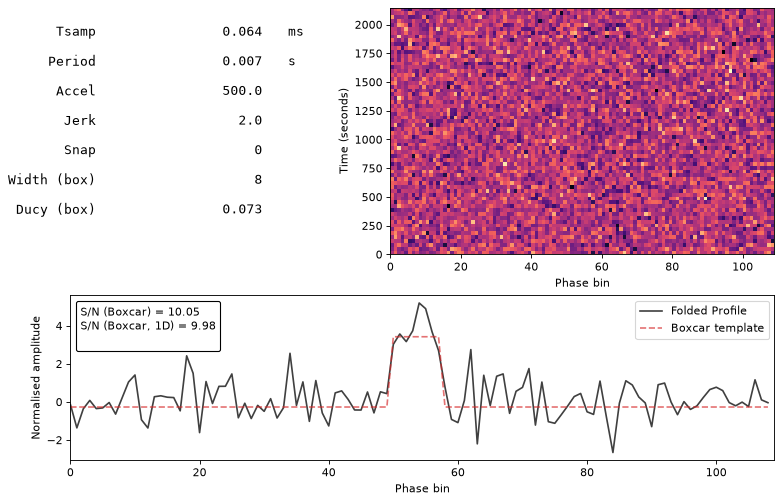

In [2]:
accel, jerk = 500.0, 2.0
mod_kwargs = {"acc": accel, "jerk": jerk}
cfg = PulseSignalConfig(
    period=0.007,
    dt=64e-6,
    nsamps=2**25,
    snr=10.0,
    ducy=0.1,
    mod_kwargs=mod_kwargs,
    seed=SEED,
)
tim_data = cfg.generate(shape="gaussian")
print(f"T_obs = {cfg.tobs:.1f} s, true frequency = {cfg.freq:.6f} Hz")
tim_data.plot_fold(cfg.freq, cfg.fold_bins, mod_kwargs=mod_kwargs, dpi=80)
plt.show()

## Search configuration and thresholds

Jerk within ±2.5 m/s³; `ParamLimits.from_upper` widens the acceleration
and frequency (142–144 Hz) intervals by the drift that jerk range can
cause. The schedule is designed for loki's default `target_snr` for three
parameters, 9.2, below the injected 10: the design assumes a pulse folded
without loss, while the search loses some S/N to its finite parameter grid
and to the pulse shape.

In [3]:
limits = ParamLimits.from_upper((142.0, 144.0), [jerk, accel], (-2.5, 2.5), cfg.tobs)
for name, (lo, hi) in zip(["jerk", "accel", "freq"], limits.limits, strict=True):
    print(f"{name:>5}: [{lo:.6g}, {hi:.6g}]")
search_cfg = PulsarSearchConfig(
    nsamps=cfg.nsamps,
    tsamp=cfg.dt,
    nbins=64,
    eta=1,
    param_limits=limits.limits,
    bseg_brute=cfg.nsamps // 8192,
    nsegments=128,
    prune_poly_order=3,
    nthreads=NTHREADS,
    ducy_max=0.5,
    wtsp=1.2,
    use_fourier=True,
)
plan = FFAPlanBase(search_cfg)
branching_pattern = np.asarray(plan.get_branching_pattern(), dtype=np.float32)
n_trees = plan.ncoords[-1]

target_snr, ref_ducy = search_cfg.target_snr, 0.1
dts = libloki.thresholds.DynamicThresholdScheme(
    branching_pattern,
    ref_ducy,
    search_cfg.nbins,
    snr_final=target_snr,
    ducy_max=search_cfg.ducy_max,
    wtsp=search_cfg.wtsp,
    mode="improved",
    beam_width=2.0,
    nthreads=NTHREADS,
    seed=SEED,
)
dts.run(thres_neigh=10, show_progress=False)
thresholds = np.asarray(dts.get_best_path_thresholds(min_pd=0.1), dtype=np.float32)
expected = libloki.thresholds.evaluate_scheme(
    thresholds,
    branching_pattern,
    ref_ducy,
    search_cfg.nbins,
    ntrials=2**14,
    snr_final=target_snr,
    ducy_max=search_cfg.ducy_max,
    wtsp=search_cfg.wtsp,
    seed=SEED + 1,  # fresh trials, not the threshold search's
)
print(
    f"{len(branching_pattern)} stages, {n_trees} trees; "
    f"P_d per run = {expected['success_h1_cumul'][-1]:.3f} (on fresh trials)",
)

 jerk: [-2.5, 2.5]
accel: [-2184.35, 3184.35]
 freq: [141.063, 144.95]


127 stages, 6261 trees; P_d per run = 0.083 (on fresh trials)


The branching pattern (mean number of children per node at each stage)
and the number of leaves the schedule expects to survive in all trees
together, against the `max_sugg` cap of a run.

[4.   9.   1.   2.09 1.44 3.   1.   9.   1.   1.   3.   1.   1.   2.09 1.44
 3.   1.   3.   1.   1.   1.   1.   1.   3.   2.2  1.37 1.   1.   1.   1.
 1.   1.   1.   1.53 1.96 1.   1.   1.   1.   1.   1.   1.   1.   2.09 1.44
 1.   1.   1.   1.   3.   1.   1.   1.   3.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   2.13 1.41 1.   1.
 1.   2.19 1.37 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.53 1.96
 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.   1.   1.  ]


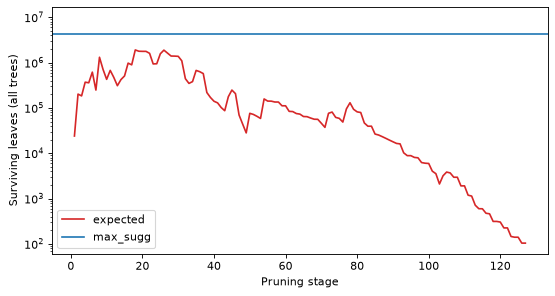

In [4]:
max_sugg = 2**22
print(np.array2string(branching_pattern, precision=2, max_line_width=78))

stages = np.arange(1, len(branching_pattern) + 1)
fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
ax.semilogy(stages, expected["complexity"] * n_trees, c="tab:red", label="expected")
ax.axhline(max_sugg, c="tab:blue", label="max_sugg")
ax.set_xlabel("Pruning stage")
ax.set_ylabel("Surviving leaves (all trees)")
ax.set_ylim(None, 4 * max_sugg)
ax.legend()
plt.show()

## Run the search

32 independent runs: with `P_d ≈ 0.1` each, the pulsar is found with
probability about `1 - 0.9^32 ≈ 0.97`.

In [5]:
ep = EPMultiPassFourier(
    search_cfg,
    thresholds,
    n_runs=32,
    max_sugg=max_sugg,
    batch_size=1024,
    poly_basis="taylor",
    show_progress=False,
)
ep.execute(tim_data.ts_e, tim_data.ts_v, outdir=str(OUTDIR), file_prefix="jerk")
result_file = next(OUTDIR.glob("jerk_*_results.h5"))

## Candidates

The best final leaves over all runs (`S/N (EP)`: pruning score; `S/N`:
boxcar S/N of the final fold).

In [6]:
true_values = {"jerk": jerk, "accel": accel, "freq": cfg.freq}
print(
    f"True parameters: jerk = {jerk:.3f}, accel = {accel:.3f}, freq = {cfg.freq:.10f}",
)
pgram = ScatteredPeriodogram.load(str(result_file))
print(pgram.get_summary_cands(10, score_type="score", run_id=None))

leaves = pgram.data
near = (
    (abs(leaves["jerk"] - jerk) < 0.05)
    & (abs(leaves["accel"] - accel) < 2.0)
    & (abs(leaves["freq"] - cfg.freq) < 1e-4)
)
print(f"\nruns that kept the pulsar: {leaves.loc[near, 'run_id'].nunique()} of 32")

True parameters: jerk = 2.000, accel = 500.000, freq = 142.8571428571
Top candidates:
dparams: djerk: 0.0007582614233, daccel: 0.203544585, dfreq: 2.299372669e-05
Run: 122_31, S/N (EP): 8.85, S/N: 9.58, jerk: 1.99986, accel: 499.84, freq: 142.857141
Run: 122_31, S/N (EP): 7.35, S/N: 9.45, jerk: 2.00062, accel: 499.90, freq: 142.857187
Run: 122_31, S/N (EP): 8.60, S/N: 9.20, jerk: 1.99910, accel: 499.99, freq: 142.857102
Run: 122_31, S/N (EP): 8.22, S/N: 8.93, jerk: 1.99910, accel: 499.78, freq: 142.857107
Run: 122_31, S/N (EP): 7.27, S/N: 8.43, jerk: 1.99986, accel: 499.84, freq: 142.857164
Run: 122_31, S/N (EP): 8.23, S/N: 8.38, jerk: 1.99910, accel: 499.99, freq: 142.857079
Run: 127_32, S/N (EP): 9.12, S/N: 8.27, jerk: 1.99845, accel: 500.02, freq: 142.857056
Run: 057_15, S/N (EP): 7.13, S/N: 7.99, jerk: 0.00838, accel: 1.94, freq: 143.855010
Run: 040_11, S/N (EP): 7.64, S/N: 7.87, jerk: -0.18078, accel: 673.90, freq: 143.933777
Run: 094_24, S/N (EP): 7.69, S/N: 7.86, jerk: 1.47566, 

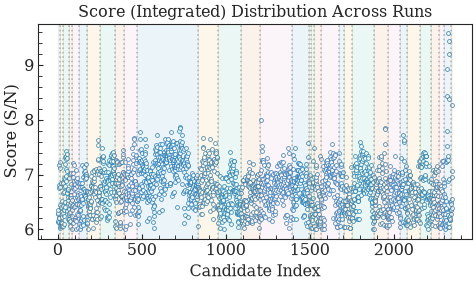

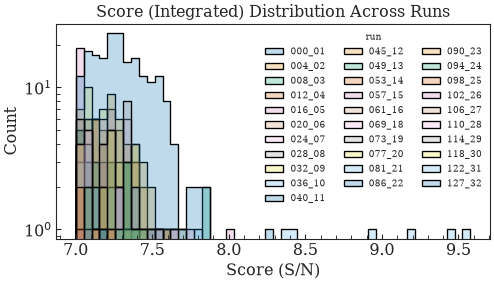

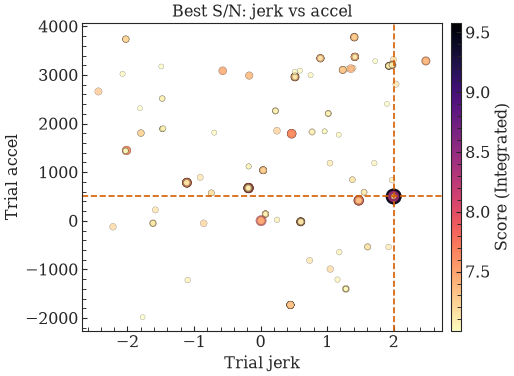

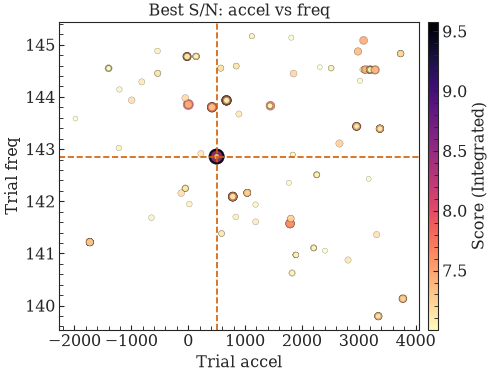

In [7]:
pgram.plot_scores(kind="scatter", run_id=None, snr_min=6, dpi=80)
plt.show()
pgram.plot_scores(kind="hist", run_id=None, snr_min=7, dpi=80)
plt.show()
pgram.plot_correlation(
    "jerk",
    "accel",
    true_values=true_values,
    run_id=None,
    snr_min=7,
    figsize=(7, 5),
    dpi=80,
)
plt.show()
pgram.plot_correlation(
    "accel",
    "freq",
    true_values={k: true_values[k] for k in ("accel", "freq")},
    run_id=None,
    snr_min=7,
    figsize=(7, 5),
    dpi=80,
)
plt.show()

## Tree size: expected vs measured

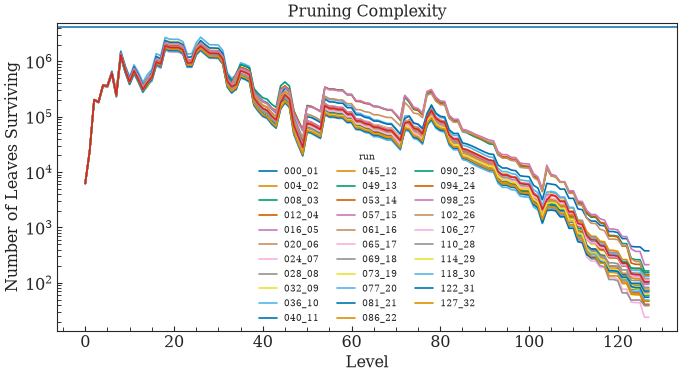

In [8]:
pstats = PruningStatsPlotter.load(str(result_file))
fig = pstats.plot_level_stats(run_id=None, dpi=80)
stages = np.arange(0, len(branching_pattern) + 1)
ax = fig.axes[0]
ax.plot(
    stages,
    np.concatenate(([1], expected["complexity"])) * n_trees,
    c="tab:red",
    label="expected",
)
ax.axhline(max_sugg, c="tab:blue", label="max_sugg")
plt.show()